# Painter Classification — Compact PyTorch CNN + SVM

## `train_1.zip → pretrained MobileNetV3-Small → embeddings → Linear SVM`

This notebook uses a compact ImageNet-pretrained MobileNetV3-Small instead of training a large CNN from scratch.

Pipeline:
1. Match ZIP images to artists in `train_info.csv`
2. Keep artists with at least `MIN_IMAGES_PER_ARTIST` matched paintings
3. Create a stratified train/validation split
4. Fine-tune a compact pretrained CNN
5. Extract 256-D embeddings and tune a linear hinge-loss classifier
6. Evaluate accuracy and F1, then save the model artifacts

The saved run matched 5,787 locally extracted paintings to 1,240 artists. Requiring at least five paintings per artist retained **4,089 paintings across 379 artists**. The reported scores use a stratified validation split.

To reproduce the dataset locally, use the original extracted subset with `train_info.csv`. The notebook checks the project directory and then `local_review/` for the dataset. The archive contains 11,025 images. Extracting the full archive changes the input set and requires retraining and evaluating the models.

In [36]:
# ============================================================
# 1. CONFIGURATION
# ============================================================

from pathlib import Path

# Use an existing extracted dataset before attempting to unpack the archive.
REVIEW_DIR = Path("local_review")
EXTRACT_DIR = Path("train_1_extracted")
if not EXTRACT_DIR.is_dir() and (REVIEW_DIR / EXTRACT_DIR).is_dir():
    EXTRACT_DIR = REVIEW_DIR / EXTRACT_DIR

ZIP_PATH = Path("train_1.zip")
if not ZIP_PATH.is_file() and (REVIEW_DIR / ZIP_PATH).is_file():
    ZIP_PATH = REVIEW_DIR / ZIP_PATH
    if not EXTRACT_DIR.is_dir():
        EXTRACT_DIR = REVIEW_DIR / "train_1_extracted"

INFO_PATH = Path("train_info.csv")

CNN_SAVE_PATH = "painter_mobilenetv3_small.pt"
SVM_SAVE_PATH = "painter_mobilenet_svm.joblib"
SCALER_SAVE_PATH = "mobilenet_embedding_scaler.joblib"
LABEL_ENCODER_SAVE_PATH = "mobilenet_label_encoder.joblib"

# Raising this threshold improves learnability but excludes rare artists.
# The saved run uses five matched paintings per artist as its minimum.
MIN_IMAGES_PER_ARTIST = 5

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

EPOCHS = 15
HEAD_EPOCHS = 3
LEARNING_RATE = 3e-4
FINETUNE_LEARNING_RATE = 1e-5
WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 5

VAL_SIZE = 0.20
RANDOM_STATE = 42

PENULTIMATE_SIZE = 256
SVM_ALPHA_VALUES = [1e-6, 1e-5, 1e-4, 1e-3]

SAMPLE_IMAGE = None

print("Configuration loaded.")

Configuration loaded.


## 2. Dependencies and pretrained weights

Install the packages if they are missing, then restart the kernel. The first model build downloads MobileNetV3-Small's pretrained ImageNet weights; later runs use the local Torch cache.

The notebook uses PyTorch for the CNN and scikit-learn for the linear SVM. The pretrained backbone is frozen at first, then its final feature blocks are fine-tuned.

In [37]:
#%pip install numpy pandas matplotlib seaborn scikit-learn pillow tqdm joblib torch torchvision

In [38]:
# ============================================================
# 3. IMPORTS + GPU CHECK
# ============================================================

import os
import random
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.linear_model import SGDClassifier

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.models import MobileNet_V3_Small_Weights

import joblib

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

print("PyTorch:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)

PyTorch: 2.14.1+cu130
Device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
CUDA: 13.0


In [39]:
# ============================================================
# 4. EXTRACT DATASET
# ============================================================

if not EXTRACT_DIR.is_dir():
    if not ZIP_PATH.is_file():
        raise FileNotFoundError(
            "Place train_1_extracted/ or train_1.zip in the project folder "
            "or local_review/ before running the data preparation cells."
        )
    print("Extracting dataset...")
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(EXTRACT_DIR)
else:
    print("Extraction directory already exists.")

print("Extraction directory:", EXTRACT_DIR)

Extraction directory already exists.
Extraction directory: train_1_extracted


In [40]:
# ============================================================
# 5. LOAD train_info.csv
# ============================================================

info = pd.read_csv(INFO_PATH)

print("CSV shape:", info.shape)
print("Columns:", list(info.columns))
display(info.head())

CSV shape: (79433, 6)
Columns: ['filename', 'artist', 'title', 'style', 'genre', 'date']


,filename,artist,title,style,genre,date
0,102257.jpg,5b39c876740bfc1cfaf544721c43cac3,Uriel,Color Field Painting,abstract,1955.0
1,75232.jpg,5b39c876740bfc1cfaf544721c43cac3,Vir Heroicus Sublimis,Color Field Painting,abstract,1950.0
2,29855.jpg,96e5bc98488ed589b9bf17ad9fd09371,Night March of a Hundred Demons (left half),Yamato-e,mythological painting,NaN
3,62252.jpg,5b39c876740bfc1cfaf544721c43cac3,"Who’s Afraid of Red, Yellow and Blue II",Color Field Painting,abstract,NaN
4,63861.jpg,5b39c876740bfc1cfaf544721c43cac3,Black Fire I,Color Field Painting,abstract,1963.0


In [41]:
# ============================================================
# 6. MATCH CSV FILENAMES TO EXTRACTED IMAGES
# ============================================================

# Build a lookup by basename so this works even if the ZIP
# contains nested folders.

image_files = []
for root, _, files in os.walk(EXTRACT_DIR):
    for filename in files:
        if filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp")):
            image_files.append(os.path.join(root, filename))

image_lookup = {
    os.path.basename(path): path
    for path in image_files
}

print("Images found in the extraction directory:", len(image_files))

if "filename" not in info.columns:
    raise ValueError(
        "Expected a 'filename' column in train_info.csv. "
        f"Found: {list(info.columns)}"
    )

# Detect artist column.
if "artist" in info.columns:
    ARTIST_COLUMN = "artist"
elif "artist_name" in info.columns:
    ARTIST_COLUMN = "artist_name"
elif "artistId" in info.columns:
    ARTIST_COLUMN = "artistId"
else:
    # Use the first non-filename column as a fallback.
    candidates = [c for c in info.columns if c != "filename"]
    if not candidates:
        raise ValueError("Could not find an artist column in train_info.csv.")
    ARTIST_COLUMN = candidates[0]

dataset = info.copy()
dataset["path"] = dataset["filename"].map(image_lookup)
dataset["artist"] = dataset[ARTIST_COLUMN]

dataset = dataset.dropna(subset=["path", "artist"]).reset_index(drop=True)

print("Matched images:", len(dataset))
print("Artist column used:", ARTIST_COLUMN)
print("Number of artists before filtering:", dataset["artist"].nunique())

display(dataset.head())

Images found in ZIP: 5787
Matched images: 5787
Artist column used: artist
Number of artists before filtering: 1240


,filename,artist,title,style,genre,date,path
0,102257.jpg,5b39c876740bfc1cfaf544721c43cac3,Uriel,Color Field Painting,abstract,1955.0,train_1_extracted/train_1/102257.jpg
1,1164.jpg,69f42fe50ebe0a46b3428b6ca22c1453,The Mall in St. James's Park,Rococo,landscape,1783,train_1_extracted/train_1/1164.jpg
2,13689.jpg,b2a43738fde0a20062a0900417351a9f,Christ driving the Traders from the Temple,Mannerism (Late Renaissance),religious painting,1600,train_1_extracted/train_1/13689.jpg
3,10709.jpg,b5585b3588ad36b108f43145a63c488f,The Life of St. Ignatius Loyola. Plate 1. Igna...,Art Nouveau (Modern),history painting,NaN,train_1_extracted/train_1/10709.jpg
4,1127.jpg,67c1053cde05250df99a1d173e57003a,The Love Letter,Baroque,genre painting,c.1669,train_1_extracted/train_1/1127.jpg


Total matched images: 5787
Total artists: 1240

Images per artist:


count    1240.000000
mean        4.666935
std         5.765910
min         1.000000
25%         1.000000
50%         2.500000
75%         5.000000
max        41.000000
Name: count, dtype: float64

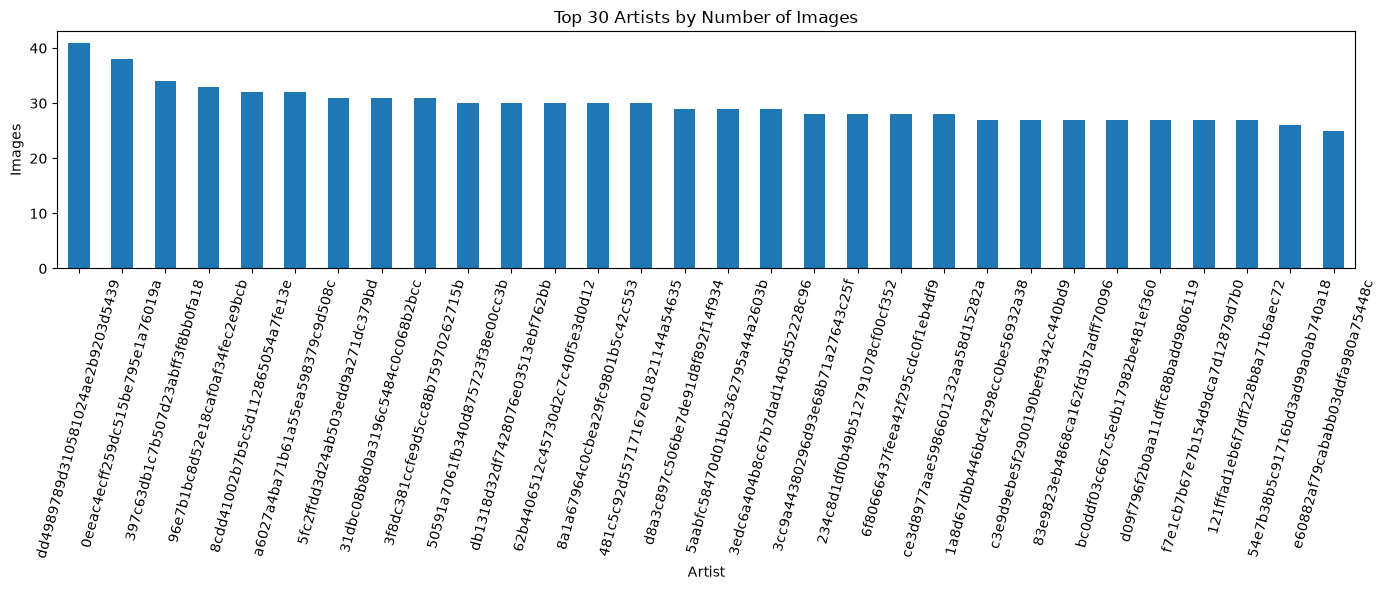

In [42]:
# ============================================================
# 7. BASIC EDA
# ============================================================

class_counts = dataset["artist"].value_counts()

print("Total matched images:", len(dataset))
print("Total artists:", dataset["artist"].nunique())
print()
print("Images per artist:")
display(class_counts.describe())

plt.figure(figsize=(14, 6))
class_counts.head(30).plot(kind="bar")
plt.title("Top 30 Artists by Number of Images")
plt.xlabel("Artist")
plt.ylabel("Images")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

## 8. Prepare labels

An artist needs at least five matched paintings to enter the saved experiment. Changing this threshold changes the classification task. Each retained artist needs examples in both splits for the per-artist evaluation.

In [43]:
before_images = len(dataset)
before_classes = dataset["artist"].nunique()

counts = dataset["artist"].value_counts()
valid_artists = counts[counts >= MIN_IMAGES_PER_ARTIST].index

dataset = dataset[
    dataset["artist"].isin(valid_artists)
].reset_index(drop=True)

print("Minimum images per artist:", MIN_IMAGES_PER_ARTIST)
print("Images removed:", before_images - len(dataset))
print("Classes removed:", before_classes - dataset["artist"].nunique())
print("Images remaining:", len(dataset))
print("Classes remaining:", dataset["artist"].nunique())

Minimum images per artist: 5
Images removed: 1698
Classes removed: 861
Images remaining: 4089
Classes remaining: 379


In [ ]:
# ============================================================
# 9. LABEL ENCODING + STRATIFIED SPLIT
# ============================================================

label_encoder = LabelEncoder()

dataset["label"] = label_encoder.fit_transform(
    dataset["artist"]
)

NUM_CLASSES = len(label_encoder.classes_)

train_df, val_df = train_test_split(
    dataset,
    test_size=VAL_SIZE,
    random_state=RANDOM_STATE,
    stratify=dataset["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Number of classes:", NUM_CLASSES)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))

# Part A — Fine-tune a compact pretrained CNN

The feature extractor is **MobileNetV3-Small**, pretrained on ImageNet. Its backbone is much smaller than the previous custom CNN and starts with useful visual features rather than random weights.

The notebook first trains a 256-D embedding head, then fine-tunes only the final backbone blocks. The classifier output size is set from the filtered artist labels.

In [45]:
# ============================================================
# 10. PYTORCH DATASET + DATALOADERS
# ============================================================

from PIL import ImageFile, ImageOps

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


class ResizeWithPadding:
    def __init__(self, size):
        self.size = size

    def __call__(self, image):
        return ImageOps.pad(
            image,
            self.size,
            method=Image.Resampling.BICUBIC,
            color=(124, 116, 104)
        )


train_transform = transforms.Compose([
    ResizeWithPadding(IMG_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.05,
        hue=0.01
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = transforms.Compose([
    ResizeWithPadding(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])


class PainterDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        with Image.open(row["path"]) as img:
            image = img.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        label = int(row["label"])
        return image, label


ImageFile.LOAD_TRUNCATED_IMAGES = True
train_dataset = PainterDataset(train_df, transform=train_transform)
val_dataset = PainterDataset(val_df, transform=eval_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=4,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    pin_memory=torch.cuda.is_available()
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 103
Validation batches: 26


In [46]:
# ============================================================
# 11. BUILD COMPACT PRETRAINED CNN
# ============================================================

class PainterCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        weights = MobileNet_V3_Small_Weights.DEFAULT
        self.backbone = models.mobilenet_v3_small(weights=weights)
        feature_size = self.backbone.classifier[0].in_features
        self.backbone.classifier = nn.Identity()

        self.embedding_head = nn.Sequential(
            nn.Linear(feature_size, PENULTIMATE_SIZE),
            nn.LayerNorm(PENULTIMATE_SIZE),
            nn.Hardswish()
        )
        self.classifier = nn.Sequential(
            nn.Dropout(0.30),
            nn.Linear(PENULTIMATE_SIZE, num_classes)
        )

        for parameter in self.backbone.parameters():
            parameter.requires_grad = False

    def unfreeze_last_blocks(self):
        for parameter in self.backbone.features[-2:].parameters():
            parameter.requires_grad = True

    def forward(self, x, return_embedding=False):
        features = self.backbone(x)
        embedding = self.embedding_head(features)

        if return_embedding:
            return embedding

        return self.classifier(embedding)


cnn = PainterCNN(NUM_CLASSES).to(device)

parameter_count = sum(parameter.numel() for parameter in cnn.parameters())
trainable_count = sum(
    parameter.numel() for parameter in cnn.parameters()
    if parameter.requires_grad
)
print(f"Total parameters: {parameter_count:,}")
print(f"Initially trainable parameters: {trainable_count:,}")
print(cnn)

Total parameters: 1,172,635
Initially trainable parameters: 245,627
PainterCNN(
  (backbone): MobileNetV3(
    (features): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
        (2): Hardswish()
      )
      (1): InvertedResidual(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=16, bias=False)
            (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
            (2): ReLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(16, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 16, kernel_size=(1, 1), stride=(1, 1))
            (activat

In [47]:
# ============================================================
# 12. QUICK FORWARD-PASS TEST
# ============================================================

sample_images, sample_labels = next(iter(train_loader))
sample_images = sample_images.to(device)
cnn.eval()

with torch.no_grad():
    sample_outputs = cnn(sample_images)
    sample_embeddings = cnn(sample_images, return_embedding=True)

expected_logits = (sample_images.shape[0], NUM_CLASSES)
expected_embeddings = (sample_images.shape[0], PENULTIMATE_SIZE)

print("Input shape:", tuple(sample_images.shape))
print("Output shape:", tuple(sample_outputs.shape))
print("Embedding shape:", tuple(sample_embeddings.shape))

assert tuple(sample_outputs.shape) == expected_logits
assert tuple(sample_embeddings.shape) == expected_embeddings

del sample_images, sample_outputs, sample_embeddings
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Input shape: (32, 3, 224, 224)
Output shape: (32, 379)
Embedding shape: (32, 256)


In [48]:
# ============================================================
# 13. TRAIN CNN WITH HEAD-FIRST FINE-TUNING
# ============================================================

criterion = nn.CrossEntropyLoss()


def make_optimizer(model):
    parameter_groups = [{
        "params": list(model.embedding_head.parameters())
        + list(model.classifier.parameters()),
        "lr": LEARNING_RATE
    }]

    trainable_backbone = [
        parameter for parameter in model.backbone.parameters()
        if parameter.requires_grad
    ]
    if trainable_backbone:
        parameter_groups.append({
            "params": trainable_backbone,
            "lr": FINETUNE_LEARNING_RATE
        })

    return optim.AdamW(parameter_groups, weight_decay=WEIGHT_DECAY)


optimizer = make_optimizer(cnn)
best_val_loss = float("inf")
epochs_without_improvement = 0
history = []

for epoch in range(EPOCHS):
    if epoch == HEAD_EPOCHS:
        cnn.unfreeze_last_blocks()
        optimizer = make_optimizer(cnn)
        print("Unfroze the final MobileNet feature blocks.")

    cnn.train()
    cnn.backbone.eval()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS}"
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        outputs = cnn(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        train_correct += (outputs.argmax(dim=1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    cnn.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = cnn(images)
            loss = criterion(outputs, labels)
            val_loss_sum += loss.item() * images.size(0)
            val_correct += (outputs.argmax(dim=1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total
    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        torch.save(
            {
                "architecture": "mobilenet_v3_small",
                "model_state_dict": cnn.state_dict(),
                "num_classes": NUM_CLASSES,
                "embedding_size": PENULTIMATE_SIZE,
                "classes": label_encoder.classes_.tolist(),
                "epoch": epoch + 1
            },
            CNN_SAVE_PATH
        )
        print("  Saved best CNN.")
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print("Early stopping: validation loss did not improve.")
            break

Epoch 1/15: 100%|██████████| 103/103 [00:42<00:00,  2.42it/s]


Epoch 1/15 | Train Loss: 5.8292 | Train Acc: 0.0180 | Val Loss: 5.5263 | Val Acc: 0.0562
  Saved best CNN.


Epoch 2/15: 100%|██████████| 103/103 [00:34<00:00,  2.99it/s]


Epoch 2/15 | Train Loss: 5.3062 | Train Acc: 0.0770 | Val Loss: 5.1734 | Val Acc: 0.0844
  Saved best CNN.


Epoch 3/15: 100%|██████████| 103/103 [00:35<00:00,  2.92it/s]


Epoch 3/15 | Train Loss: 4.8406 | Train Acc: 0.1434 | Val Loss: 4.8891 | Val Acc: 0.1210
  Saved best CNN.
Unfroze the final MobileNet feature blocks.


... (20 outputs left out)

Epoch 14/15: 100%|██████████| 103/103 [00:33<00:00,  3.08it/s]


Epoch 14/15 | Train Loss: 1.6270 | Train Acc: 0.7897 | Val Loss: 3.7280 | Val Acc: 0.2689
  Saved best CNN.


Epoch 15/15: 100%|██████████| 103/103 [00:31<00:00,  3.23it/s]


Epoch 15/15 | Train Loss: 1.3825 | Train Acc: 0.8450 | Val Loss: 3.6941 | Val Acc: 0.2763
  Saved best CNN.


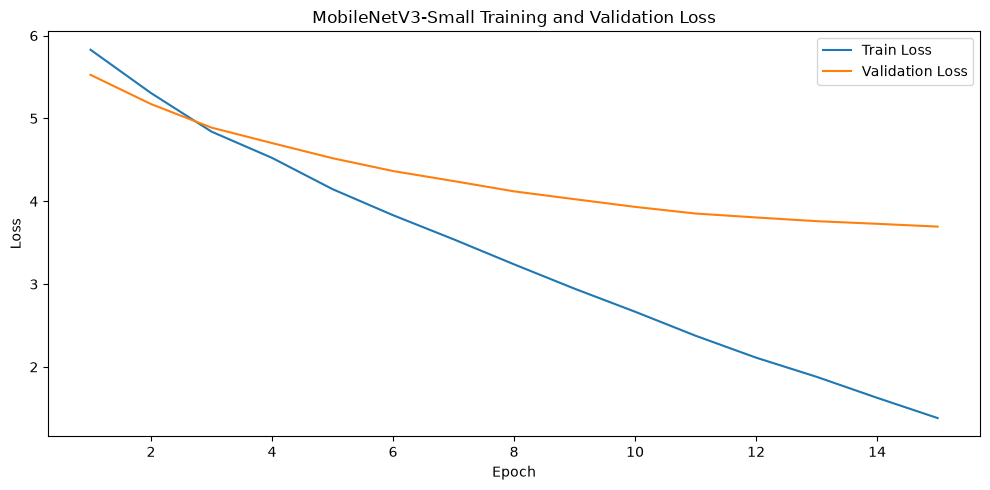

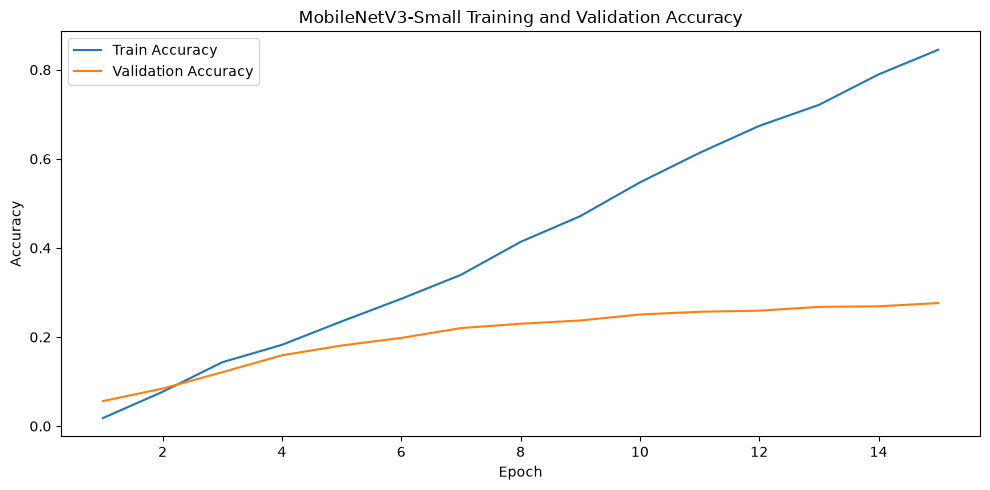

In [49]:
# ============================================================
# 14. TRAINING CURVES
# ============================================================

history_df = pd.DataFrame(history)

plt.figure(figsize=(10, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], label="Train Loss")
plt.plot(history_df["epoch"], history_df["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MobileNetV3-Small Training and Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(history_df["epoch"], history_df["train_accuracy"], label="Train Accuracy")
plt.plot(history_df["epoch"], history_df["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV3-Small Training and Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

# Part B — Extract 256-dimensional CNN embeddings

For each image, the embedding head produces a vector of 256 features immediately before the artist classifier. These vectors are the inputs to the linear SVM.

In [50]:
# ============================================================
# 15. LOAD BEST CNN
# ============================================================

checkpoint = torch.load(
    CNN_SAVE_PATH,
    map_location=device,
    weights_only=False
)

if checkpoint.get("architecture") != "mobilenet_v3_small":
    raise ValueError("Checkpoint architecture does not match this notebook.")

if checkpoint.get("classes") != label_encoder.classes_.tolist():
    raise ValueError(
        "Checkpoint labels do not match the current filtered dataset. "
        "Rerun the CNN training cell before extracting embeddings."
    )

cnn.load_state_dict(checkpoint["model_state_dict"])
cnn.eval()

print("Loaded best CNN from epoch:", checkpoint["epoch"])

Loaded best CNN from epoch: 15


In [51]:
# ============================================================
# 16. EXTRACT EMBEDDINGS
# ============================================================

def extract_embeddings(model, loader, device):
    model.eval()
    all_embeddings = []
    all_labels = []

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Extracting embeddings"):
            images = images.to(device, non_blocking=True)
            embeddings = model(images, return_embedding=True)
            all_embeddings.append(embeddings.cpu().numpy())
            all_labels.append(labels.numpy())

    return (
        np.concatenate(all_embeddings, axis=0),
        np.concatenate(all_labels, axis=0)
    )


X_train, y_train = extract_embeddings(cnn, train_loader, device)
X_val, y_val = extract_embeddings(cnn, val_loader, device)

print("Training embeddings:", X_train.shape)
print("Validation embeddings:", X_val.shape)

assert X_train.shape == (len(train_df), PENULTIMATE_SIZE)
assert X_val.shape == (len(val_df), PENULTIMATE_SIZE)
assert np.array_equal(np.unique(y_train), np.arange(NUM_CLASSES))
assert np.array_equal(np.unique(y_val), np.arange(NUM_CLASSES))

Extracting embeddings: 100%|██████████| 26/26 [00:08<00:00,  3.08it/s]

Training embeddings: (3271, 256)
Validation embeddings: (818, 256)


Embedding dimension: 256
Mean embedding norm: 15.107303
Std embedding norm: 0.4349727


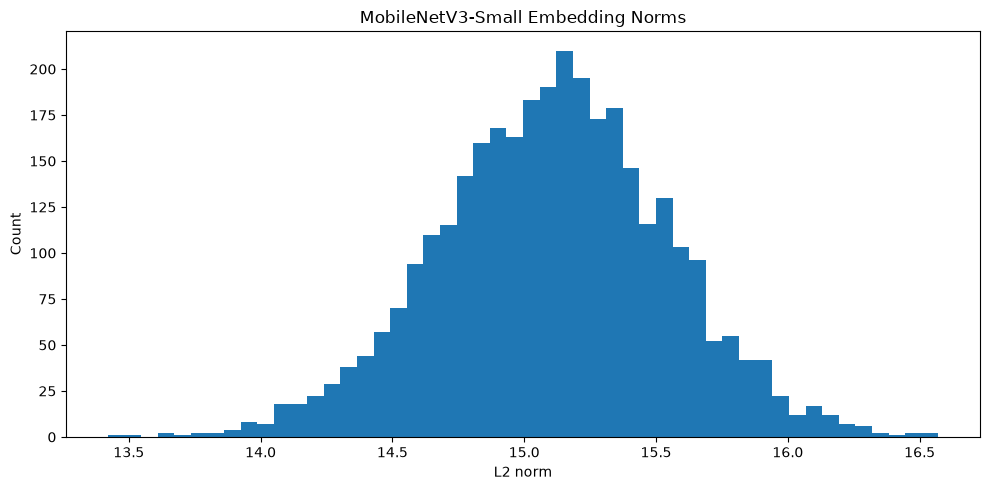

In [52]:
# ============================================================
# 17. EMBEDDING EDA
# ============================================================

if not np.isfinite(X_train).all() or not np.isfinite(X_val).all():
    raise ValueError("Non-finite CNN embeddings detected.")

embedding_norms = np.linalg.norm(X_train, axis=1)

print("Embedding dimension:", X_train.shape[1])
print("Mean embedding norm:", embedding_norms.mean())
print("Std embedding norm:", embedding_norms.std())

plt.figure(figsize=(10, 5))
plt.hist(embedding_norms, bins=50)
plt.xlabel("L2 norm")
plt.ylabel("Count")
plt.title("MobileNetV3-Small Embedding Norms")
plt.tight_layout()
plt.show()

# Part C — Standardize embeddings and train Linear SVM

In [53]:
# ============================================================
# 18. STANDARDIZE EMBEDDINGS
# ============================================================

assert X_train.shape[1] == PENULTIMATE_SIZE
assert X_val.shape[1] == PENULTIMATE_SIZE

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print("Scaled train shape:", X_train_scaled.shape)
print("Scaled validation shape:", X_val_scaled.shape)

joblib.dump(scaler, SCALER_SAVE_PATH)
joblib.dump(label_encoder, LABEL_ENCODER_SAVE_PATH)

Scaled train shape: (3271, 256)
Scaled validation shape: (818, 256)


['mobilenet_label_encoder.joblib']

In [54]:
print("Embedding dimension:", X_train.shape[1])
print("Scaled train shape:", X_train_scaled.shape)
print("Scaled validation shape:", X_val_scaled.shape)
print("Train labels:", y_train.shape)
print("Validation labels:", y_val.shape)

assert X_train_scaled.shape[1] == PENULTIMATE_SIZE
assert X_val_scaled.shape[1] == PENULTIMATE_SIZE

Embedding dimension: 256
Scaled train shape: (3271, 256)
Scaled validation shape: (818, 256)
Train labels: (3271,)
Validation labels: (818,)


In [55]:
# ============================================================
# 19. TUNE LINEAR HINGE CLASSIFIER
# ============================================================

import time

svm_results = []
best_macro_f1 = -1.0
svm_model = None

for alpha in SVM_ALPHA_VALUES:
    start_time = time.time()
    print(f"Training hinge classifier with alpha={alpha:g}")

    candidate = SGDClassifier(
        loss="hinge",
        alpha=alpha,
        max_iter=1000,
        tol=1e-3,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    candidate.fit(X_train_scaled, y_train)
    candidate_pred = candidate.predict(X_val_scaled)

    candidate_accuracy = accuracy_score(y_val, candidate_pred)
    candidate_macro_f1 = f1_score(
        y_val,
        candidate_pred,
        average="macro",
        zero_division=0
    )
    candidate_weighted_f1 = f1_score(
        y_val,
        candidate_pred,
        average="weighted",
        zero_division=0
    )

    svm_results.append({
        "alpha": alpha,
        "accuracy": candidate_accuracy,
        "macro_f1": candidate_macro_f1,
        "weighted_f1": candidate_weighted_f1,
        "fit_seconds": time.time() - start_time
    })

    if candidate_macro_f1 > best_macro_f1:
        best_macro_f1 = candidate_macro_f1
        svm_model = candidate

svm_results_df = pd.DataFrame(svm_results).sort_values(
    "macro_f1",
    ascending=False
).reset_index(drop=True)

display(svm_results_df)
print("Selected alpha:", svm_results_df.iloc[0]["alpha"])

Training hinge classifier with alpha=1e-06
Training hinge classifier with alpha=1e-05
Training hinge classifier with alpha=0.0001
Training hinge classifier with alpha=0.001


,alpha,accuracy,macro_f1,weighted_f1,fit_seconds
0,0.000001,0.272616,0.204438,0.247928,0.871292
1,0.000010,0.260391,0.193218,0.235264,0.595133
2,0.000100,0.262836,0.192485,0.237862,0.583270
3,0.001000,0.243276,0.130286,0.191087,0.440556


Selected alpha: 1e-06


In [56]:
# ============================================================
# 20. EVALUATE AND SAVE FINAL SVM
# ============================================================

svm = svm_model
val_predictions = svm.predict(X_val_scaled)

accuracy = accuracy_score(y_val, val_predictions)
macro_f1 = f1_score(y_val, val_predictions, average="macro", zero_division=0)
weighted_f1 = f1_score(y_val, val_predictions, average="weighted", zero_division=0)

print("Selected alpha:", svm_results_df.iloc[0]["alpha"])
print(f"Validation Accuracy:    {accuracy:.4f}")
print(f"Validation Macro-F1:    {macro_f1:.4f}")
print(f"Validation Weighted-F1: {weighted_f1:.4f}")

joblib.dump(svm, SVM_SAVE_PATH)
print(f"Model saved to: {SVM_SAVE_PATH}")

Selected alpha: 1e-06
Validation Accuracy:    0.2726
Validation Macro-F1:    0.2044
Validation Weighted-F1: 0.2479
Model saved to: painter_mobilenet_svm.joblib


In [57]:
# ============================================================
# 21. CLASSIFICATION REPORT
# ============================================================

expected_labels = np.arange(NUM_CLASSES)
if not np.array_equal(np.unique(y_val), expected_labels):
    raise RuntimeError(
        "Validation labels do not cover every retained class. "
        "Rerun the label/split and embedding cells in order."
    )

print(
    classification_report(
        y_val,
        val_predictions,
        labels=expected_labels,
        target_names=[str(name) for name in label_encoder.classes_],
        zero_division=0
    )
)

                                  precision    recall  f1-score   support

0052cc81f35d53736ab860be16fc07f4       0.00      0.00      0.00         1
012bd50d44685a367716570e252c7556       0.00      0.00      0.00         1
02b866899dc71a00364337e830d075d7       0.00      0.00      0.00         2
03f28fbdb3d6543f4b0d9307d0b7da00       0.00      0.00      0.00         1
040827f8fb458d1cea7d3e0b9e33132f       0.33      1.00      0.50         1
041b8f718d4ea537b14762cccc012d87       1.00      1.00      1.00         1
059d590e174c545474f0fedcc126ce4c       1.00      0.50      0.67         2
062244b785e58518f2f189329633c59e       0.00      0.00      0.00         3
0682c5c8975d0d3514685b555b2f143d       0.00      0.00      0.00         1
06f82951366bafca791e325cb6b214ac       0.00      0.00      0.00         1
072592d6fa48c2ef2d5d248c0478e890       0.00      0.00      0.00         2
079af364947be8a33dae3435712aa5f3       1.00      1.00      1.00         1
0925b0aeb81b5e69033ea61a09d15e11     

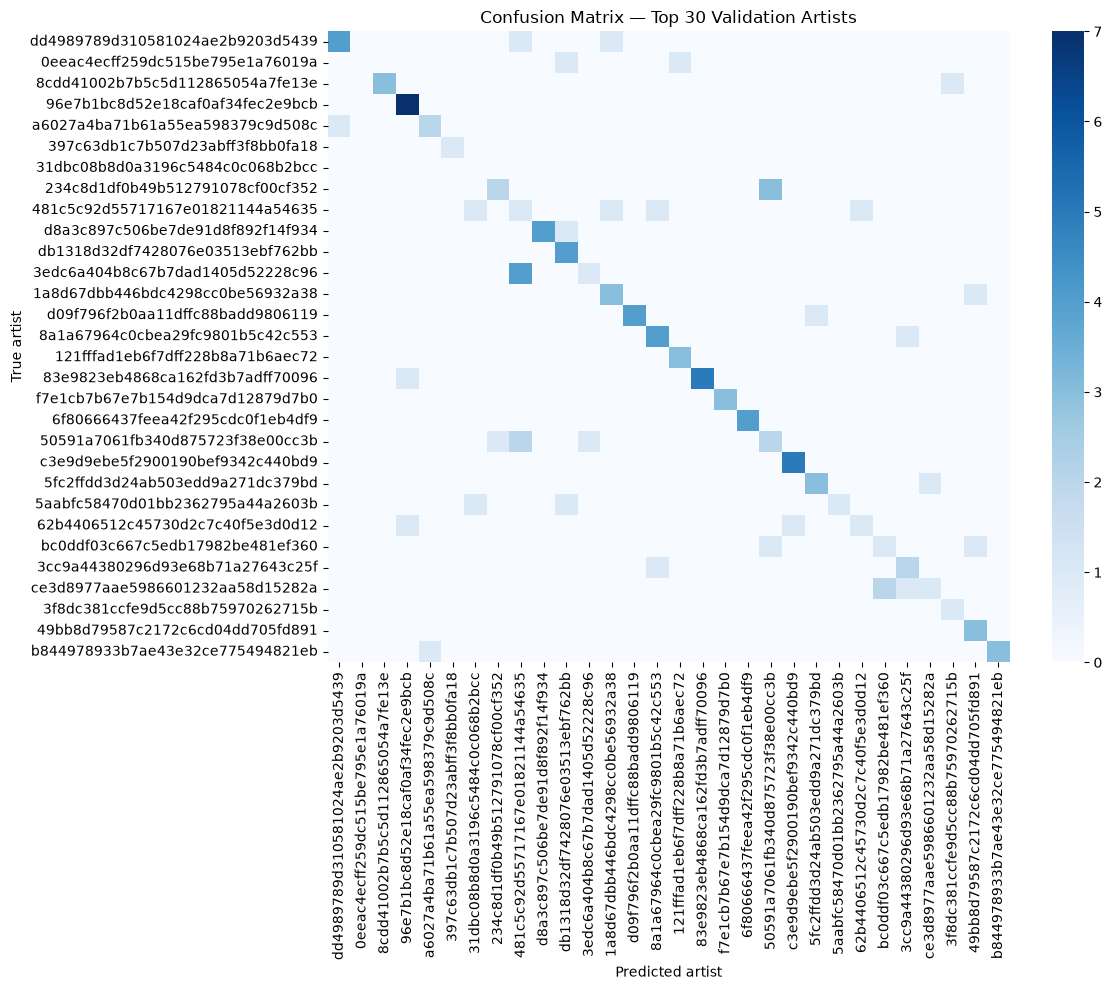

In [58]:
# ============================================================
# 22. CONFUSION MATRIX — TOP VALIDATION ARTISTS
# ============================================================

top_n = min(30, NUM_CLASSES)
top_labels = (
    pd.Series(y_val)
    .value_counts()
    .head(top_n)
    .index
    .to_numpy()
)

cm = confusion_matrix(y_val, val_predictions, labels=top_labels)
top_names = label_encoder.inverse_transform(top_labels)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=top_names,
    yticklabels=top_names
)
plt.xlabel("Predicted artist")
plt.ylabel("True artist")
plt.title(f"Confusion Matrix — Top {top_n} Validation Artists")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 23. Optional single-image prediction

Set `SAMPLE_IMAGE` to an image path if you want to run the complete CNN → SVM pipeline on one painting.

In [59]:
# ============================================================
# 23. SINGLE-IMAGE PREDICTION
# ============================================================

def predict_single_image(
    image_path,
    cnn,
    svm,
    scaler,
    label_encoder,
    device
):
    cnn.eval()

    with Image.open(image_path) as image_file:
        image = image_file.convert("RGB")
        tensor = eval_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        embedding = cnn(
            tensor,
            return_embedding=True
        ).cpu().numpy()

    embedding_scaled = scaler.transform(embedding)
    predicted_label = svm.predict(embedding_scaled)[0]
    return label_encoder.inverse_transform([predicted_label])[0]


if SAMPLE_IMAGE is not None:
    prediction = predict_single_image(
        SAMPLE_IMAGE,
        cnn,
        svm,
        scaler,
        label_encoder,
        device
    )
    print("Predicted painter:", prediction)
else:
    print("Set SAMPLE_IMAGE to an image path to run a prediction.")

Set SAMPLE_IMAGE to an image path to run a prediction.


## Final model summary

The final system is:

```text
Painting image
     ↓
ImageNet-pretrained MobileNetV3-Small
     ↓
256-D embedding
     ↓
StandardScaler
     ↓
Tuned linear hinge classifier
     ↓
Painter class
```

The saved run used 3,271 training images and 818 validation images across 379 artists. The CNN head reached **27.63% validation accuracy**. The linear SVM reached **27.26% validation accuracy** and **0.2044 macro-F1**. The same validation set was used for checkpoint and regularization selection.

Model files for prediction:

- `painter_mobilenetv3_small.pt`
- `painter_mobilenet_svm.joblib`
- `mobilenet_embedding_scaler.joblib`
- `mobilenet_label_encoder.joblib`